# Projet 10 – Prédire le prix des maisons (Boston Housing)
## Notebook d'amélioration du modèle de régression linéaire

Ce notebook **complète** le travail existant (`cours_housingdata_corrige (1).ipynb` pour l'exploration et `tp_esgis_housingdata.ipynb` pour le modèle). Il ajoute ce que le sujet demande et qui manquait :

| Manque identifié | Ce qui est fait ici |
|---|---|
| Pas de régression linéaire **simple** | Section 3 : MEDV ~ LSTAT et MEDV ~ RM |
| Pas de **MSE** ni de **MAPE**, RMSE seulement sur l'entraînement | Section 2 : une fonction unique qui calcule R², MSE, RMSE, MAE et MAPE |
| Pas de séparation **entraînement / test** | Section 1 : 80 % / 20 %, plus une validation croisée à 5 plis |
| Imputation calculée sur tout le jeu (fuite de données) | Médianes calculées **uniquement sur l'entraînement** |
| Modèle du TP incohérent avec l'EDA (B, CRIM brut, RAD + TAX) | Section 5 : modèle corrigé |
| Résidus en U (relation non linéaire) | Section 6 : log(LSTAT) et RM² |

**Démarche** : on compare 4 modèles sur **le même jeu de test** pour mesurer objectivement chaque amélioration.

## 0. Bibliothèques et paramètres

In [1]:
import warnings, json, os
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.model_selection import train_test_split, KFold
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200)
SEED = 42                      # graine fixée : résultats reproductibles
FIG = 'figures_amelioration'   # dossier où l'on sauvegarde les graphiques
os.makedirs(FIG, exist_ok=True)

## 1. Chargement et séparation entraînement / test

On sépare les données **avant** tout traitement. Le jeu de test (20 %, soit 102 quartiers) joue le rôle de « nouveaux quartiers » que le modèle n'a jamais vus : c'est la seule façon honnête de mesurer sa capacité à **prédire**.

In [2]:
df = pd.read_csv('HousingData.csv', sep=';')
print('Dimensions :', df.shape)

train, test = train_test_split(df, test_size=0.2, random_state=SEED)
print(f'Entraînement : {len(train)} quartiers | Test : {len(test)} quartiers')

Dimensions : (506, 14)
Entraînement : 404 quartiers | Test : 102 quartiers


### Préparation des variables (sans fuite de données)

- Les **médianes d'imputation** sont calculées sur l'entraînement seulement, puis appliquées au test.
- On crée les transformations identifiées dans l'EDA : `log_CRIM` (asymétrie), `log_LSTAT` et `RM2` (non-linéarités).

In [3]:
A_IMPUTER = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'AGE', 'LSTAT']

def preparer(d, medianes):
    d = d.copy()
    for c in A_IMPUTER:
        d[c] = d[c].fillna(medianes[c])
    d['CHAS'] = d['CHAS'].astype(int)
    d['log_CRIM'] = np.log1p(d['CRIM'])     # réduit l'asymétrie de CRIM (5,3 -> 1,4)
    d['log_LSTAT'] = np.log(d['LSTAT'])     # capte la courbure LSTAT / MEDV
    d['RM2'] = d['RM'] ** 2                 # effet croissant des grandes surfaces
    return d

medianes_train = train[A_IMPUTER].median()
tr = preparer(train, medianes_train)
te = preparer(test, medianes_train)
print('Médianes utilisées (calculées sur l\'entraînement) :')
print(medianes_train.round(3).to_dict())

Médianes utilisées (calculées sur l'entraînement) :
{'CRIM': 0.261, 'ZN': 0.0, 'INDUS': 8.56, 'CHAS': 0.0, 'AGE': 76.95, 'LSTAT': 10.97}


## 2. Les métriques d'évaluation

| Métrique | Formule | Lecture |
|---|---|---|
| **R²** | $1 - \frac{\sum (y-\hat y)^2}{\sum (y-\bar y)^2}$ | Part de la variance du prix expliquée (1 = parfait) |
| **MSE** | $\frac{1}{n}\sum (y-\hat y)^2$ | Erreur quadratique moyenne (en k$²) : pénalise fortement les grosses erreurs |
| **RMSE** | $\sqrt{MSE}$ | Erreur « typique », dans l'unité du prix (k$) |
| **MAE** | $\frac{1}{n}\sum \lvert y-\hat y\rvert$ | Erreur absolue moyenne (k$), moins sensible aux extrêmes |
| **MAPE** | $\frac{100}{n}\sum \left\lvert \frac{y-\hat y}{y}\right\rvert$ | Erreur moyenne **en %** du prix réel : la plus parlante pour le métier |

In [4]:
def metriques(y, y_pred):
    y, y_pred = np.asarray(y, float), np.asarray(y_pred, float)
    e = y - y_pred
    mse = np.mean(e ** 2)
    return {'R2': 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2),
            'MSE': mse,
            'RMSE': np.sqrt(mse),
            'MAE': np.mean(np.abs(e)),
            'MAPE (%)': np.mean(np.abs(e / y)) * 100}

def ajuster(variables, data=tr, cov='nonrobust'):
    X = sm.add_constant(data[variables])
    return sm.OLS(data['MEDV'], X).fit(cov_type=cov)

def predire(modele, variables, data):
    return modele.predict(sm.add_constant(data[variables], has_constant='add'))

def evaluer(nom, variables):
    m = ajuster(variables)
    res_tr = metriques(tr['MEDV'], m.fittedvalues)
    res_te = metriques(te['MEDV'], predire(m, variables, te))
    return m, {'Modèle': nom, 'Nb variables': len(variables),
               'R2 train': res_tr['R2'], **{k + ' test': v for k, v in res_te.items()}}

## 3. Régression linéaire simple

On commence par le modèle le plus simple : **une seule variable explicative**. On teste les deux facteurs les plus corrélés au prix dans l'EDA : `LSTAT` (r = −0,72) et `RM` (r = +0,70).

$$MEDV = \beta_0 + \beta_1 \cdot X + \varepsilon$$

In [5]:
resultats = []
modeles = {}
for v in ['LSTAT', 'RM']:
    m, r = evaluer(f'Simple : {v}', [v])
    modeles[f'Simple : {v}'] = m
    resultats.append(r)
    print(f"MEDV = {m.params['const']:.2f} {m.params[v]:+.3f} x {v}   "
          f"(R² train = {m.rsquared:.3f}, p-value = {m.pvalues[v]:.1e})")

pd.DataFrame(resultats).set_index('Modèle').round(3)

MEDV = 34.73 -0.961 x LSTAT   (R² train = 0.515, p-value = 3.7e-65)
MEDV = -36.25 +9.348 x RM   (R² train = 0.505, p-value = 2.2e-63)


,Nb variables,R2 train,R2 test,MSE test,RMSE test,MAE test,MAPE (%) test
Modèle,,,,,,,
Simple : LSTAT,1,0.515,0.551,32.898,5.736,4.081,20.201
Simple : RM,1,0.505,0.371,46.145,6.793,4.478,25.209


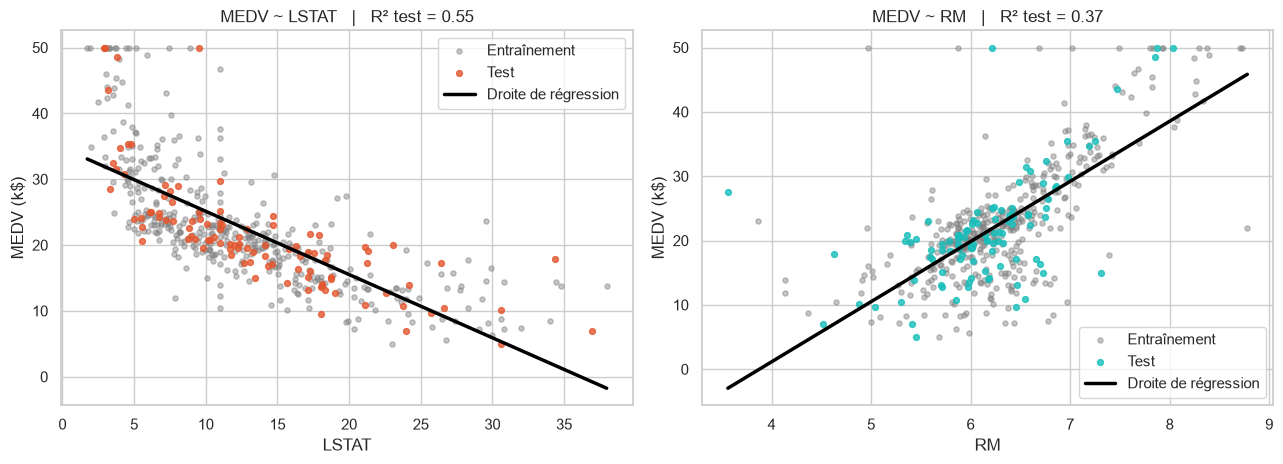

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, v, col in zip(axes, ['LSTAT', 'RM'], ['#E4572E', '#17BEBB']):
    m = modeles[f'Simple : {v}']
    ax.scatter(tr[v], tr['MEDV'], s=14, alpha=0.45, color='grey', label='Entraînement')
    ax.scatter(te[v], te['MEDV'], s=18, alpha=0.8, color=col, label='Test')
    xs = np.linspace(df[v].min(), df[v].max(), 100)
    ax.plot(xs, m.params['const'] + m.params[v] * xs, color='black', lw=2.5, label='Droite de régression')
    ax.set_xlabel(v); ax.set_ylabel('MEDV (k$)')
    ax.set_title(f"MEDV ~ {v}   |   R² test = {[r for r in resultats if r['Modèle']==f'Simple : {v}'][0]['R2 test']:.2f}")
    ax.legend()
plt.tight_layout(); plt.savefig(f'{FIG}/01_regression_simple.png', dpi=160); plt.show()

**INTERPRÉTATION**

- **LSTAT seul** explique déjà environ **52 %** de la variance du prix (R² test ≈ 0,55). Chaque point de pourcentage de population défavorisée en plus est associé à environ **−0,95 k$** de valeur médiane.
- **RM seul** : chaque pièce supplémentaire est associée à environ **+9 k$**, mais le modèle généralise moins bien (R² test ≈ 0,37).
- Le graphique de LSTAT montre clairement une **courbe** et non une droite : la baisse du prix est forte entre 0 et 10 %, puis s'aplatit. Une droite sous-estime donc les quartiers aisés et surestime les plus pauvres. Cela justifie la transformation `log(LSTAT)` de la section 6.
- Erreur moyenne d'environ **20 % (MAPE)** : une seule variable ne suffit pas, d'où la régression multiple.

## 4. Modèle de référence : le modèle du TP (régression multiple)

On reproduit **à l'identique** le modèle du notebook TP (13 variables brutes, dont `B`, `CRIM` brut, `RAD` et `TAX`), mais cette fois évalué sur le jeu de test.

In [7]:
VAR_TP = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']
m_tp, r = evaluer('Multiple : modèle du TP', VAR_TP)
modeles['Multiple : modèle du TP'] = m_tp
resultats.append(r)
print(f"R² train = {r['R2 train']:.3f}  ->  R² test = {r['R2 test']:.3f}")
print(f"RMSE test = {r['RMSE test']:.2f} k$  |  MAPE test = {r['MAPE (%) test']:.1f} %")

R² train = 0.743  ->  R² test = 0.659
RMSE test = 5.00 k$  |  MAPE test = 16.5 %


**INTERPRÉTATION**

Le R² passe d'environ 0,74 sur l'entraînement à environ **0,66 sur le test** : le modèle est un peu optimiste sur les données qu'il a déjà vues. Le R² de 0,73 annoncé dans le TP surestimait donc la performance réelle sur de nouveaux quartiers. C'est le chiffre de test qu'il faut présenter.

## 5. Modèle corrigé : cohérent avec l'EDA et éthique

On applique les décisions **déjà justifiées dans l'exploration** mais oubliées dans le TP :

| Décision | Justification |
|---|---|
| Retirer `B` | Variable construite sur l'origine ethnique : éthiquement inacceptable |
| Retirer `TAX` | Corrélée à 0,91 avec `RAD` (VIF ≈ 9) |
| Retirer `INDUS` et `AGE` | Non significatives dans le modèle du TP (p ≈ 0,5) |
| `log_CRIM` au lieu de `CRIM` | CRIM est très asymétrique |

In [8]:
VAR_CORR = ['log_CRIM', 'ZN', 'CHAS', 'NOX', 'RM', 'DIS', 'RAD', 'PTRATIO', 'LSTAT']

Xv = tr[VAR_CORR]
vif = pd.Series([variance_inflation_factor(sm.add_constant(Xv).values, i + 1) for i in range(len(VAR_CORR))],
                index=VAR_CORR).sort_values(ascending=False)
print('VIF du modèle corrigé :'); print(vif.round(2).to_string())

m_corr, r = evaluer('Multiple : modèle corrigé', VAR_CORR)
modeles['Multiple : modèle corrigé'] = m_corr
resultats.append(r)
print(f"\nR² test = {r['R2 test']:.3f} | RMSE test = {r['RMSE test']:.2f} k$ | MAPE test = {r['MAPE (%) test']:.1f} %")

VIF du modèle corrigé :
log_CRIM    4.99
RAD         4.54
NOX         3.70
DIS         3.42
LSTAT       2.36
ZN          2.10
PTRATIO     1.77
RM          1.73
CHAS        1.06

R² test = 0.661 | RMSE test = 4.98 k$ | MAPE test = 16.8 %


**INTERPRÉTATION**

- Avec **9 variables au lieu de 13**, sans la variable `B`, la performance sur le test est **identique** (R² ≈ 0,66, RMSE ≈ 5,0 k$). Les 4 variables retirées n'apportaient donc rien en prédiction.
- Tous les VIF restent sous 5 : la multicolinéarité est maîtrisée.
- **Message clé** : on gagne en simplicité, en interprétabilité et en éthique **sans rien perdre** en précision.

## 6. Modèle amélioré : prise en compte des non-linéarités

Les résidus du TP formaient un **U** : la relation n'est pas linéaire. Deux transformations, suggérées par les nuages de points de l'EDA :

- **`log(LSTAT)`** : l'effet de LSTAT est fort pour les petites valeurs puis s'atténue.
- **`RM²`** : chaque pièce supplémentaire vaut plus dans les grands logements (quartiers haut de gamme).

Le modèle reste une **régression linéaire** : linéaire dans ses coefficients, même si les variables sont transformées.

In [9]:
VAR_AMEL = ['log_CRIM', 'ZN', 'CHAS', 'NOX', 'RM', 'RM2', 'DIS', 'RAD', 'PTRATIO', 'log_LSTAT']
m_amel, r = evaluer('Multiple : modèle amélioré', VAR_AMEL)
modeles['Multiple : modèle amélioré'] = m_amel
resultats.append(r)
print(f"R² test = {r['R2 test']:.3f} | RMSE test = {r['RMSE test']:.2f} k$ | MAPE test = {r['MAPE (%) test']:.1f} %")

R² test = 0.787 | RMSE test = 3.95 k$ | MAPE test = 11.9 %


### Variante testée : prédire log(MEDV)

On a aussi testé de modéliser le **logarithme** du prix (souvent conseillé pour les prix). Cette variante est moins performante sur le test que le modèle amélioré : on la mentionne mais on ne la retient pas.

In [10]:
m_log = sm.OLS(np.log(tr['MEDV']), sm.add_constant(tr[VAR_AMEL])).fit()
pred_log = np.exp(predire(m_log, VAR_AMEL, te))
r_log = metriques(te['MEDV'], pred_log)
print({k: round(v, 3) for k, v in r_log.items()})

{'R2': np.float64(0.751), 'MSE': np.float64(18.239), 'RMSE': np.float64(4.271), 'MAE': np.float64(2.434), 'MAPE (%)': np.float64(12.423)}


## 7. Comparaison des modèles sur le jeu de test

In [11]:
tableau = pd.DataFrame(resultats).set_index('Modèle')
tableau.round(3)

,Nb variables,R2 train,R2 test,MSE test,RMSE test,MAE test,MAPE (%) test
Modèle,,,,,,,
Simple : LSTAT,1,0.515,0.551,32.898,5.736,4.081,20.201
Simple : RM,1,0.505,0.371,46.145,6.793,4.478,25.209
Multiple : modèle du TP,13,0.743,0.659,24.983,4.998,3.148,16.533
Multiple : modèle corrigé,9,0.721,0.661,24.843,4.984,3.210,16.806
Multiple : modèle amélioré,10,0.808,0.787,15.630,3.953,2.366,11.886


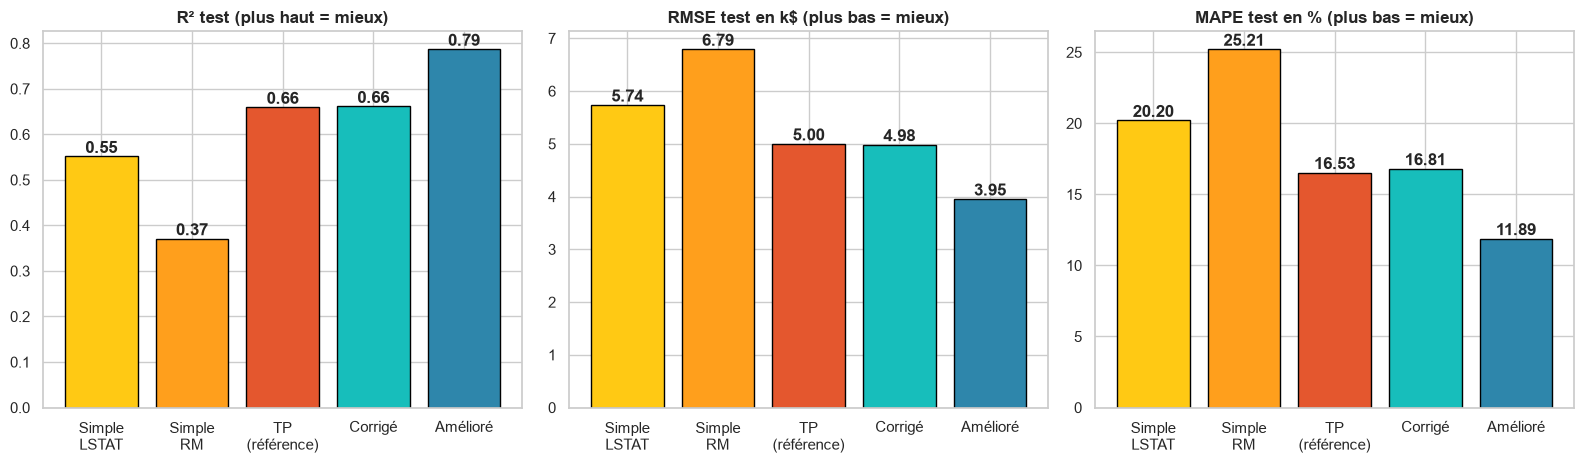

In [12]:
noms_courts = ['Simple\nLSTAT', 'Simple\nRM', 'TP\n(référence)', 'Corrigé', 'Amélioré']
couleurs = ['#FFC914', '#FF9F1C', '#E4572E', '#17BEBB', '#2E86AB']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, met, titre in zip(axes, ['R2 test', 'RMSE test', 'MAPE (%) test'],
                          ['R² test (plus haut = mieux)', 'RMSE test en k$ (plus bas = mieux)', 'MAPE test en % (plus bas = mieux)']):
    vals = tableau[met].values
    bars = ax.bar(noms_courts, vals, color=couleurs, edgecolor='black')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.2f}', ha='center', va='bottom', fontweight='bold')
    ax.set_title(titre, fontweight='bold')
plt.tight_layout(); plt.savefig(f'{FIG}/02_comparaison_modeles.png', dpi=160); plt.show()

### Validation croisée à 5 plis (robustesse)

Un seul découpage train/test peut être chanceux. On répète l'évaluation sur 5 découpages différents, **en recalculant l'imputation dans chaque pli**.

In [13]:
def validation_croisee(variables, k=5):
    rmse, r2 = [], []
    for i_tr, i_te in KFold(k, shuffle=True, random_state=SEED).split(df):
        a, b = df.iloc[i_tr], df.iloc[i_te]
        med = a[A_IMPUTER].median()
        a, b = preparer(a, med), preparer(b, med)
        m = sm.OLS(a['MEDV'], sm.add_constant(a[variables])).fit()
        res = metriques(b['MEDV'], m.predict(sm.add_constant(b[variables], has_constant='add')))
        rmse.append(res['RMSE']); r2.append(res['R2'])
    return np.mean(r2), np.std(r2), np.mean(rmse), np.std(rmse)

cv = []
for nom, var in [('Simple : LSTAT', ['LSTAT']), ('Simple : RM', ['RM']),
                 ('Multiple : modèle du TP', VAR_TP), ('Multiple : modèle corrigé', VAR_CORR),
                 ('Multiple : modèle amélioré', VAR_AMEL)]:
    r2m, r2s, rm, rs = validation_croisee(var)
    cv.append({'Modèle': nom, 'R2 CV': f'{r2m:.3f} ± {r2s:.3f}', 'RMSE CV (k$)': f'{rm:.2f} ± {rs:.2f}'})
pd.DataFrame(cv).set_index('Modèle')

,R2 CV,RMSE CV (k$)
Modèle,,
Simple : LSTAT,0.512 ± 0.052,6.36 ± 0.48
Simple : RM,0.473 ± 0.073,6.60 ± 0.53
Multiple : modèle du TP,0.708 ± 0.037,4.91 ± 0.25
Multiple : modèle corrigé,0.692 ± 0.028,5.05 ± 0.26
Multiple : modèle amélioré,0.786 ± 0.054,4.18 ± 0.55


**INTERPRÉTATION**

La validation croisée confirme le classement : le modèle amélioré reste nettement le meilleur, avec une erreur typique d'environ **4,2 k$** contre environ **4,9 k$** pour le modèle du TP. Le gain n'est donc pas dû à un découpage favorable.

## 8. Analyse des résidus : avant / après

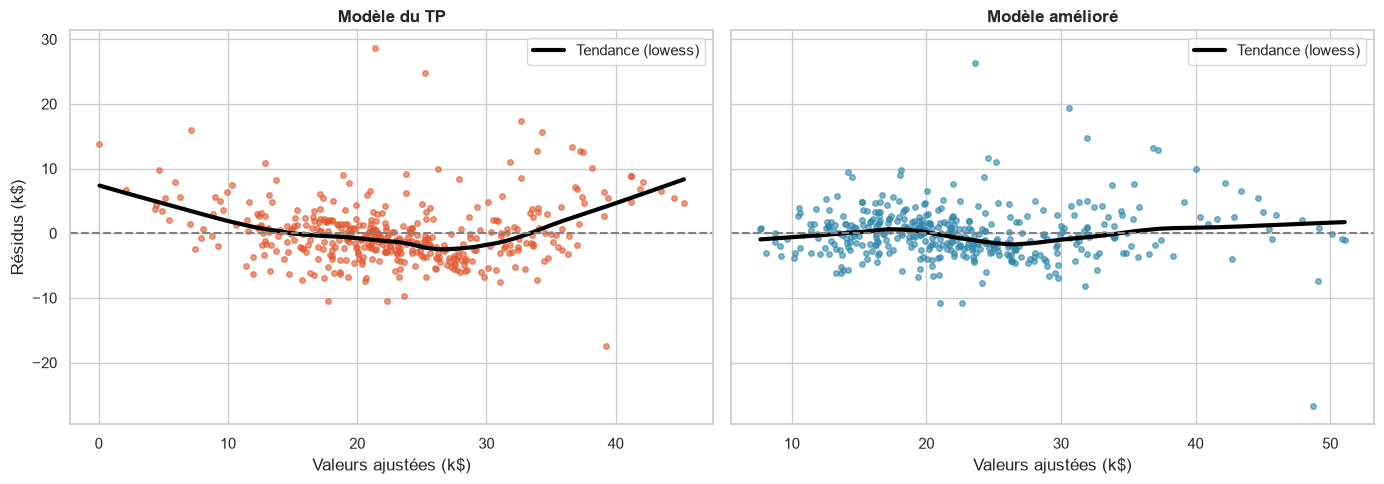

,Shapiro-Wilk p,Breusch-Pagan p,Asymétrie résidus,Écart-type résidus
Modèle,,,,
Modèle du TP,8.442316e-15,7.708485e-08,1.430762,4.733422
Modèle corrigé,7.756060e-14,1.731971e-07,1.349220,4.925271
Modèle amélioré,2.491864e-16,1.169338e-10,0.627009,4.091198


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (nom, m, col) in zip(axes, [('Modèle du TP', m_tp, '#E4572E'), ('Modèle amélioré', m_amel, '#2E86AB')]):
    ax.scatter(m.fittedvalues, m.resid, s=16, alpha=0.6, color=col)
    lw = sm.nonparametric.lowess(m.resid, m.fittedvalues, frac=0.4)
    ax.plot(lw[:, 0], lw[:, 1], color='black', lw=3, label='Tendance (lowess)')
    ax.axhline(0, color='grey', ls='--')
    ax.set_title(nom, fontweight='bold'); ax.set_xlabel('Valeurs ajustées (k$)'); ax.legend()
axes[0].set_ylabel('Résidus (k$)')
plt.tight_layout(); plt.savefig(f'{FIG}/03_residus_avant_apres.png', dpi=160); plt.show()

diag = []
for nom, m in [('Modèle du TP', m_tp), ('Modèle corrigé', m_corr), ('Modèle amélioré', m_amel)]:
    diag.append({'Modèle': nom,
                 'Shapiro-Wilk p': stats.shapiro(m.resid).pvalue,
                 'Breusch-Pagan p': het_breuschpagan(m.resid, m.model.exog)[1],
                 'Asymétrie résidus': stats.skew(m.resid),
                 'Écart-type résidus': m.resid.std()})
pd.DataFrame(diag).set_index('Modèle')

**INTERPRÉTATION**

- **Modèle du TP** : la courbe de tendance dessine un **U** net, ce qui signale une non-linéarité non captée.
- **Modèle amélioré** : la tendance devient **presque plate** autour de 0. La non-linéarité principale est corrigée, l'asymétrie des résidus est divisée par plus de 2 (1,43 → 0,63) et leur écart-type baisse (4,7 → 4,1 k$).
- Les tests de Shapiro-Wilk et de Breusch-Pagan restent significatifs : quelques quartiers atypiques (notamment ceux plafonnés à 50 k$) et une variance non parfaitement constante. On utilise donc des **erreurs-types robustes (HC3)** pour interpréter les coefficients.

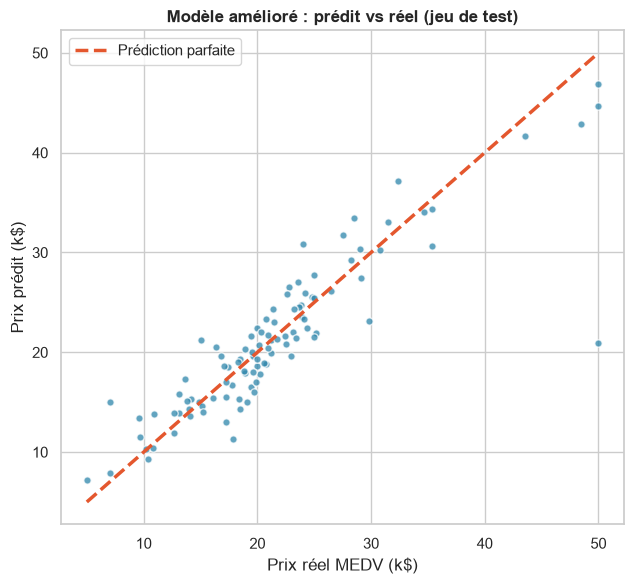

In [15]:
pred_final = predire(m_amel, VAR_AMEL, te)
plt.figure(figsize=(6.5, 6))
plt.scatter(te['MEDV'], pred_final, s=28, alpha=0.75, color='#2E86AB', edgecolor='white')
plt.plot([5, 50], [5, 50], color='#E4572E', lw=2.5, ls='--', label='Prédiction parfaite')
plt.xlabel('Prix réel MEDV (k$)'); plt.ylabel('Prix prédit (k$)')
plt.title('Modèle amélioré : prédit vs réel (jeu de test)', fontweight='bold'); plt.legend()
plt.tight_layout(); plt.savefig(f'{FIG}/04_predit_vs_reel.png', dpi=160); plt.show()

## 9. Interprétation des coefficients du modèle final

Erreurs-types robustes (HC3) : les p-values restent fiables malgré l'hétéroscédasticité.

In [16]:
m_final = ajuster(VAR_AMEL, cov='HC3')
print(m_final.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.803
Method:                 Least Squares   F-statistic:                     188.0
Date:                Fri, 27 Nov 2026   Prob (F-statistic):          5.04e-143
Time:                        18:54:56   Log-Likelihood:                -1141.9
No. Observations:                 404   AIC:                             2306.
Df Residuals:                     393   BIC:                             2350.
Df Model:                          10                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        133.4902     16.965      7.868      0.0

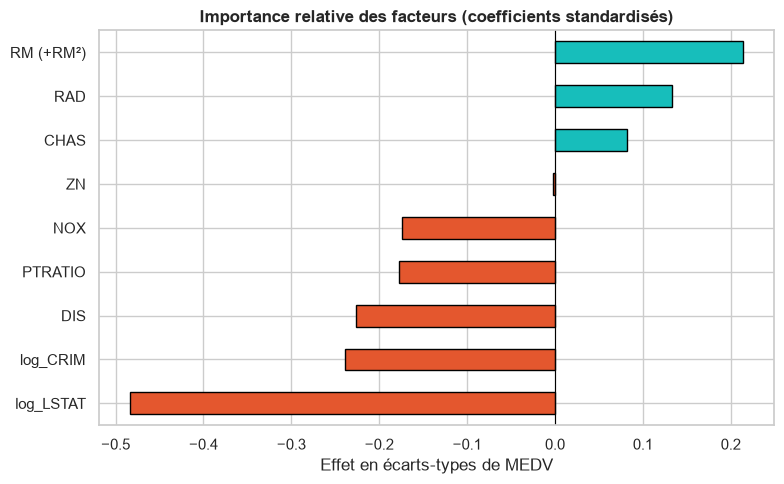

log_LSTAT   -0.484
log_CRIM    -0.239
DIS         -0.226
PTRATIO     -0.177
NOX         -0.175
ZN          -0.002
CHAS         0.082
RAD          0.133
RM (+RM²)    0.214
dtype: float64

In [17]:
## Coefficients standardisés : effet d'une hausse d'1 écart-type de X, en écarts-types de MEDV
## RM et RM2 sont regroupés via l'effet marginal de RM au point moyen
sd_y = tr['MEDV'].std()
coef_std = {}
for v in VAR_AMEL:
    if v in ('RM', 'RM2'):
        continue
    coef_std[v] = m_final.params[v] * tr[v].std() / sd_y
eff_rm = m_final.params['RM'] + 2 * m_final.params['RM2'] * tr['RM'].mean()
coef_std['RM (+RM²)'] = eff_rm * tr['RM'].std() / sd_y
coef_std = pd.Series(coef_std).sort_values()

plt.figure(figsize=(8, 5))
coef_std.plot.barh(color=['#E4572E' if v < 0 else '#17BEBB' for v in coef_std], edgecolor='black')
plt.axvline(0, color='black', lw=0.8)
plt.title('Importance relative des facteurs (coefficients standardisés)', fontweight='bold')
plt.xlabel('Effet en écarts-types de MEDV')
plt.tight_layout(); plt.savefig(f'{FIG}/05_coefficients_standardises.png', dpi=160); plt.show()
coef_std.round(3)

In [18]:
## Traduction des coefficients en langage métier (toutes choses égales par ailleurs)
p = m_final.params
def prix_rm(rm):   # contribution de RM au prix
    return p['RM'] * rm + p['RM2'] * rm ** 2

print(f"LSTAT : passer de 5 % à 10 % de population défavorisée  -> {p['log_LSTAT'] * np.log(10/5):+.2f} k$")
print(f"LSTAT : passer de 20 % à 25 %                          -> {p['log_LSTAT'] * np.log(25/20):+.2f} k$  (effet qui s'atténue)")
print(f"RM    : passer de 5 à 6 pièces                         -> {prix_rm(6) - prix_rm(5):+.2f} k$")
print(f"RM    : passer de 7 à 8 pièces                         -> {prix_rm(8) - prix_rm(7):+.2f} k$  (effet qui s'accélère)")
print(f"CHAS  : quartier au bord de la rivière                 -> {p['CHAS']:+.2f} k$")
print(f"NOX   : +0,1 de pollution (oxydes d'azote)             -> {p['NOX'] * 0.1:+.2f} k$")
print(f"PTRATIO : +1 élève par enseignant                      -> {p['PTRATIO']:+.2f} k$")
print(f"DIS   : +1 unité de distance aux centres d'emploi      -> {p['DIS']:+.2f} k$")
print(f"CRIM  : criminalité multipliée par 2 (via log)         -> {p['log_CRIM'] * np.log(2):+.2f} k$ (environ)")

LSTAT : passer de 5 % à 10 % de population défavorisée  -> -5.32 k$
LSTAT : passer de 20 % à 25 %                          -> -1.71 k$  (effet qui s'atténue)
RM    : passer de 5 à 6 pièces                         -> -0.71 k$
RM    : passer de 7 à 8 pièces                         -> +7.94 k$  (effet qui s'accélère)
CHAS  : quartier au bord de la rivière                 -> +3.02 k$
NOX   : +0,1 de pollution (oxydes d'azote)             -> -1.38 k$
PTRATIO : +1 élève par enseignant                      -> -0.74 k$
DIS   : +1 unité de distance aux centres d'emploi      -> -0.99 k$
CRIM  : criminalité multipliée par 2 (via log)         -> -1.55 k$ (environ)


**INTERPRÉTATION : les facteurs clés du prix**

1. **Le statut socio-économique (LSTAT)** est le facteur n°1 (coefficient standardisé ≈ −0,48). Passer de 5 % à 10 % de population défavorisée est associé à environ **−5,3 k$**, mais passer de 20 % à 25 % seulement à **−1,7 k$** : l'effet s'atténue.
2. **La criminalité (log_CRIM)**, **la distance aux emplois (DIS)** et **la taille des logements (RM)** suivent (≈ 0,21 à 0,24 en valeur absolue).
3. **RM a un effet croissant** : passer de 5 à 6 pièces ne change presque rien (≈ −0,7 k$), alors que passer de 7 à 8 pièces est associé à environ **+7,9 k$** (segment haut de gamme).
4. **L'environnement et les services** : pollution (NOX : −1,4 k$ pour +0,1) et ratio élèves/enseignants (PTRATIO : −0,74 k$ par élève supplémentaire) font baisser le prix.
5. **Le bord de rivière (CHAS)** est associé à une prime d'environ +3 k$, mais elle **n'est plus significative au seuil de 5 %** avec les erreurs robustes (p ≈ 0,06) : seulement 34 quartiers sont concernés. **ZN** n'est pas significatif (p ≈ 0,94) et pourrait être retiré.

⚠️ Ce sont des **associations**, pas des causes : ajouter une pièce à une maison n'augmente pas mécaniquement son prix du montant indiqué.
⚠️ Le coefficient de `RAD` est positif alors que sa corrélation simple avec le prix est négative : l'effet de RAD se mélange avec ceux de la criminalité et de la pollution. On ne l'interprète pas seul.

## 10. Exemple de prédiction (sans `input()` bloquant)

In [19]:
quartier = pd.DataFrame([{'CRIM': 0.25, 'ZN': 0, 'CHAS': 0, 'NOX': 0.54, 'RM': 6.2,
                          'DIS': 3.2, 'RAD': 5, 'PTRATIO': 19, 'LSTAT': 11.4}])
quartier['log_CRIM'] = np.log1p(quartier['CRIM'])
quartier['log_LSTAT'] = np.log(quartier['LSTAT'])
quartier['RM2'] = quartier['RM'] ** 2
pred = m_final.get_prediction(sm.add_constant(quartier[VAR_AMEL], has_constant='add')).summary_frame(alpha=0.05)
print(f"Prix médian prédit : {pred['mean'].iloc[0]:.1f} k$")
print(f"Intervalle de prédiction à 95 % : [{pred['obs_ci_lower'].iloc[0]:.1f} ; {pred['obs_ci_upper'].iloc[0]:.1f}] k$")

Prix médian prédit : 21.6 k$
Intervalle de prédiction à 95 % : [13.4 ; 29.7] k$


## 11. Sauvegarde des résultats et conclusion

In [20]:
sortie = {'tableau_test': tableau.round(4).reset_index().to_dict(orient='records'),
          'validation_croisee': cv,
          'diagnostics': pd.DataFrame(diag).round(6).to_dict(orient='records'),
          'coefficients_final_HC3': m_final.params.round(4).to_dict(),
          'pvalues_final_HC3': m_final.pvalues.round(6).to_dict(),
          'coef_standardises': coef_std.round(4).to_dict(),
          'variante_log_MEDV': {k: round(v, 4) for k, v in r_log.items()}}
with open('resultats_amelioration.json', 'w', encoding='utf-8') as f:
    json.dump(sortie, f, ensure_ascii=False, indent=2)
print('Résultats sauvegardés dans resultats_amelioration.json')

Résultats sauvegardés dans resultats_amelioration.json


### Conclusion

| | Modèle du TP | Modèle amélioré |
|---|---|---|
| Variables | 13 (dont B, RAD + TAX) | 10 (sans B ni TAX, avec log et RM²) |
| R² **test** | ≈ 0,66 | ≈ **0,79** |
| RMSE test | ≈ 5,0 k$ | ≈ **4,0 k$** |
| MAPE test | ≈ 16,5 % | ≈ **11,9 %** |
| Résidus | En U | Quasi centrés |

**Le modèle amélioré réduit l'erreur moyenne d'environ 28 %** (MAPE de 16,5 % à 11,9 %), tout en étant plus éthique et plus interprétable.

**Limites restantes** : prix plafonnés à 50 k$ (censure), données des années 1970 et agrégées par quartier, dépendance spatiale entre quartiers voisins non prise en compte.

**Pour aller plus loin** : régression Ridge/Lasso, modèle Tobit pour la censure, comparaison avec une forêt aléatoire ou du gradient boosting.